### **AhR Activity Prediction**
---

This project explores how machine learning can be used to predict whether a chemical compound activates the Aryl Hydrocarbon Receptor (AhR).

The dataset contains molecular structures in **`SMILES`** format. I use these structures to train and compare different models that classify compounds as active or inactive.

In [1]:

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.feature_extraction.text import CountVectorizer


### **Loading the Dataset**
---
First, I load the **`Tox21 NR-AhR dataset`** and prepare it for further analysis. It contains molecular structures, compound identifiers and their corresponding activity labels.

In [2]:

df = pd.read_csv(
    "data/nr-ahr.smiles",
    sep=r"\s+",
    header=None,
    names=["structure", "compound_id", "activity"]
)

df.head()


,structure,compound_id,activity
0,CC(O)=O.[H][C@@]12CCC3=CC(=CC=C3[C@@]1(C)CCC[C...,NCGC00255644-01,0
1,Cl.C[C@@H](NCCCC1=CC=CC(=C1)C(F)(F)F)C2=CC=CC3...,NCGC00181002-01,0
2,CC(C)OC(=O)C1=C(C)NC(N)=C(C1C2=CC(=CC=C2)[N+](...,NCGC00167436-01,0
3,Cl.CN(C)C(=O)C1(CCN(CCC2(CN(CCO2)C(=O)C3=CC=CC...,NCGC00254013-01,0
4,Cl.CCOC(=O)O[C@H](C)OC(=O)C1=CC=C2N(CC3=NOC(=C...,NCGC00254071-01,0


### **Exploring the Data**
---
Before training the models, I take a closer look at the dataset. I check its size, column types, missing values and the distribution of active and inactive compounds.

In [3]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum())

print("\nClass distribution:")
print(df["activity"].value_counts())

print("\nRelative class distribution:")
print(df["activity"].value_counts(normalize=True))


Dataset shape: (8169, 3)

Column names:
Index(['structure', 'compound_id', 'activity'], dtype='str')

Data types:
structure        str
compound_id      str
activity       int64
dtype: object

Missing values per column:
structure      0
compound_id    0
activity       0
dtype: int64

Class distribution:
activity
0    7219
1     950
Name: count, dtype: int64

Relative class distribution:
activity
0    0.883707
1    0.116293
Name: proportion, dtype: float64


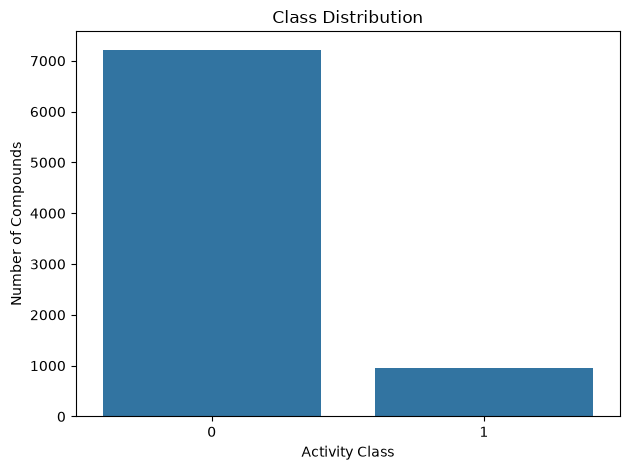

In [4]:

sns.countplot(data=df, x="activity")

plt.title("Class Distribution")
plt.xlabel("Activity Class")
plt.ylabel("Number of Compounds")
plt.tight_layout()
plt.show()


### **Preparing the Data**
---
I use the molecular structures as input and the activity labels as the target. The dataset is split into training and test data, while keeping the class distribution similar in both sets.

In [5]:

X_text = df["structure"]
y = df["activity"]

print("Target variable:", y.name)
print("Unique classes:", y.unique())


Target variable: activity
Unique classes: [0 1]


In [6]:

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


### **Turning SMILES into Features**
---
Machine learning models need numerical input, so the SMILES strings are converted into character-based features with **`CountVectorizer`**. **`lowercase=False`** matters here: in SMILES notation an uppercase **`C`** is an aliphatic carbon and a lowercase **`c`** an aromatic one, so folding the case would throw away chemical information. The vocabulary is learned from the training split only — if the test set helped build it, the model would already know something about data it is supposed to see for the first time.

In [7]:

vectorizer = CountVectorizer(
    analyzer="char",
    ngram_range=(1, 2),
    lowercase=False
)

X_train = vectorizer.fit_transform(X_train_text)

X_test = vectorizer.transform(X_test_text)

print("Number of features:", X_train.shape[1])



Number of features: 488


### **Training and Comparing Models**
---
I start with a simple baseline model and then test several classifiers. This gives me a first comparison of how well the models identify active compounds.

In [8]:

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)

print("DummyClassifier Accuracy:", accuracy_score(y_test, y_pred_dummy))



DummyClassifier Accuracy: 0.8837209302325582


In [9]:

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

print("LogisticRegression Accuracy:", accuracy_score(y_test, y_pred_log))


LogisticRegression Accuracy: 0.8929008567931457


### **Handling Class Imbalance**
---
The dataset contains many more inactive than active compounds. I use class weighting to give the less common active class more influence during training.

In [10]:

log_model_bal = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

log_model_bal.fit(X_train, y_train)

y_pred_log_bal = log_model_bal.predict(X_test)

print("LogisticRegression (Balanced) Accuracy:", accuracy_score(y_test, y_pred_log_bal))


LogisticRegression (Balanced) Accuracy: 0.7833537331701347


In [11]:

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("DecisionTreeClassifier Accuracy:", accuracy_score(y_test, y_pred_tree))



DecisionTreeClassifier Accuracy: 0.8947368421052632


In [12]:

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("RandomForestClassifier Accuracy:", accuracy_score(y_test, y_pred_rf))


RandomForestClassifier Accuracy: 0.9228886168910648


In [13]:

rf_model_bal = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

rf_model_bal.fit(X_train, y_train)

y_pred_rf_bal = rf_model_bal.predict(X_test)

print("RandomForestClassifier (Balanced) Accuracy:", accuracy_score(y_test, y_pred_rf_bal))


RandomForestClassifier (Balanced) Accuracy: 0.9222766217870257


In [14]:

rf_model_sub = RandomForestClassifier(
    random_state=42,
    class_weight="balanced_subsample"
)

rf_model_sub.fit(X_train, y_train)

y_pred_rf_sub = rf_model_sub.predict(X_test)

print("RandomForestClassifier (Balanced Subsample) Accuracy:", accuracy_score(y_test, y_pred_rf_sub))


RandomForestClassifier (Balanced Subsample) Accuracy: 0.9247246022031824


### **Tuning the Random Forest**
---
After comparing the initial models, I focus on the Random Forest. I use a pipeline with GridSearchCV to test different parameter combinations.

The pipeline also ensures that CountVectorizer is fitted separately within each cross-validation fold.

In [15]:

rf_pipeline = Pipeline([
    ("vectorizer", CountVectorizer(
        analyzer="char",
        ngram_range=(1, 2),
        lowercase=False
    )),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])


In [16]:

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 20, 40],
    "classifier__min_samples_leaf": [1, 2, 4]
}


In [17]:

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)


In [18]:

rf_grid.fit(X_train_text, y_train)


Fitting 5 folds for each of 27 candidates, totalling 135 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [None, 20, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metriceva

In [19]:

y_pred_rf_tuned = rf_grid.predict(X_test_text)

print("RandomForest (Tuned)")
print(classification_report(y_test, y_pred_rf_tuned, zero_division=0))


RandomForest (Tuned)
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      1444
           1       0.68      0.65      0.66       190

    accuracy                           0.92      1634
   macro avg       0.82      0.81      0.81      1634
weighted avg       0.92      0.92      0.92      1634



In [20]:

print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(rf_grid.best_score_)


Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}

Best Cross-Validation F1-Score:
0.6364206779548673


### **Evaluating the Models**
---
Accuracy alone does not tell the whole story. The baseline reaches 88 % accuracy simply by predicting every compound as inactive.

I therefore focus on precision, recall and F1-score for class 1, which represents the active compounds.

In [21]:

print("DummyClassifier")
print(classification_report(y_test, y_pred_dummy, zero_division=0))

print("LogisticRegression")
print(classification_report(y_test, y_pred_log, zero_division=0))

print("LogisticRegression (Balanced)")
print(classification_report(y_test, y_pred_log_bal, zero_division=0))

print("DecisionTreeClassifier")
print(classification_report(y_test, y_pred_tree, zero_division=0))

print("RandomForestClassifier")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("RandomForestClassifier (Balanced)")
print(classification_report(y_test, y_pred_rf_bal, zero_division=0))

print("RandomForestClassifier (Balanced Subsample)")
print(classification_report(y_test, y_pred_rf_sub, zero_division=0))

print("RandomForestClassifier (Tuned)")
print(classification_report(y_test, y_pred_rf_tuned, zero_division=0))


DummyClassifier
              precision    recall  f1-score   support

           0       0.88      1.00      0.94      1444
           1       0.00      0.00      0.00       190

    accuracy                           0.88      1634
   macro avg       0.44      0.50      0.47      1634
weighted avg       0.78      0.88      0.83      1634

LogisticRegression
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      1444
           1       0.60      0.24      0.34       190

    accuracy                           0.89      1634
   macro avg       0.75      0.61      0.64      1634
weighted avg       0.87      0.89      0.87      1634

LogisticRegression (Balanced)
              precision    recall  f1-score   support

           0       0.96      0.79      0.87      1444
           1       0.32      0.75      0.45       190

    accuracy                           0.78      1634
   macro avg       0.64      0.77      0.66      1634
weighted 

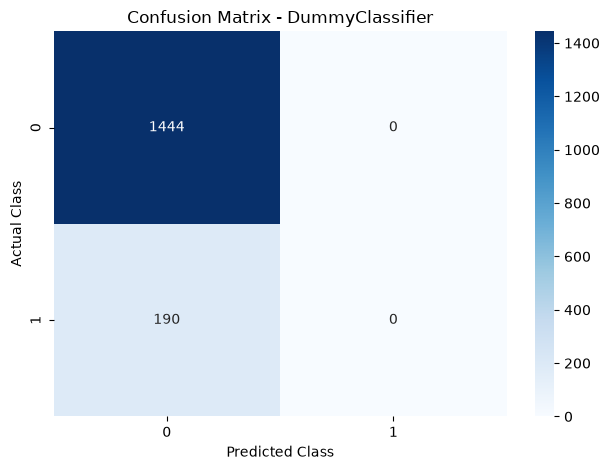

In [22]:

cm_dummy = confusion_matrix(y_test, y_pred_dummy)

sns.heatmap(cm_dummy, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - DummyClassifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


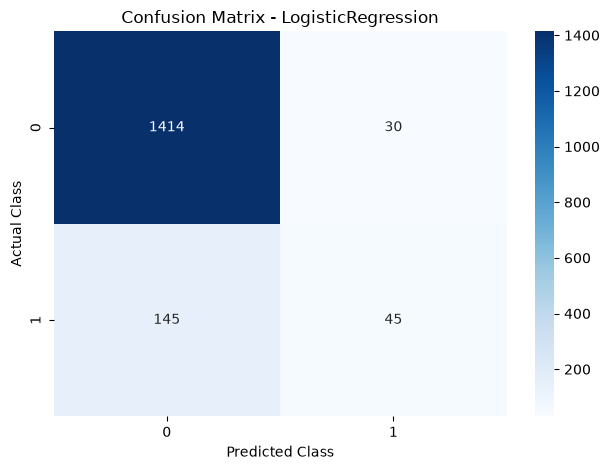

In [23]:

cm_log = confusion_matrix(y_test, y_pred_log)

sns.heatmap(cm_log, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - LogisticRegression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


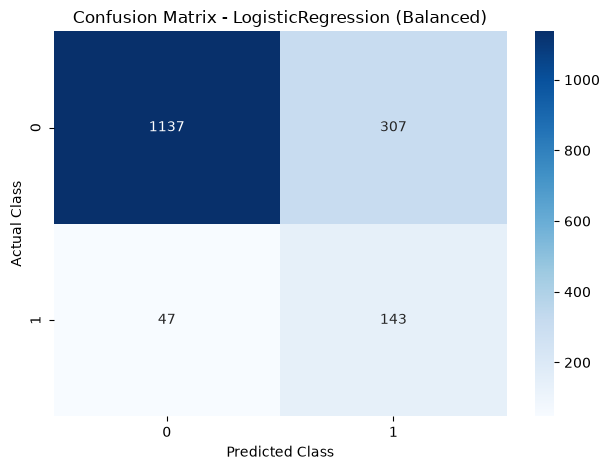

In [24]:

cm_log_bal = confusion_matrix(y_test, y_pred_log_bal)

sns.heatmap(cm_log_bal, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - LogisticRegression (Balanced)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


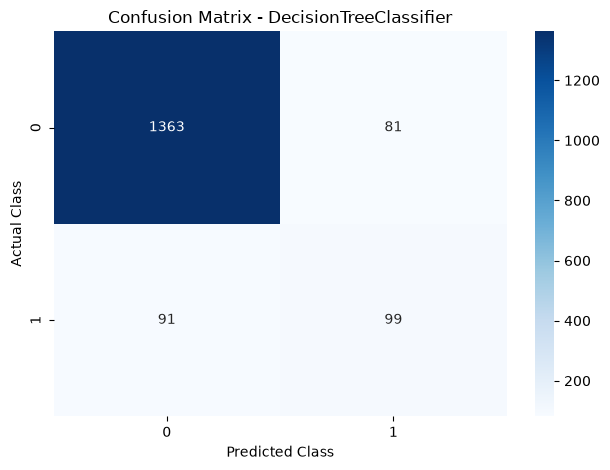

In [25]:

cm_tree = confusion_matrix(y_test, y_pred_tree)

sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - DecisionTreeClassifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


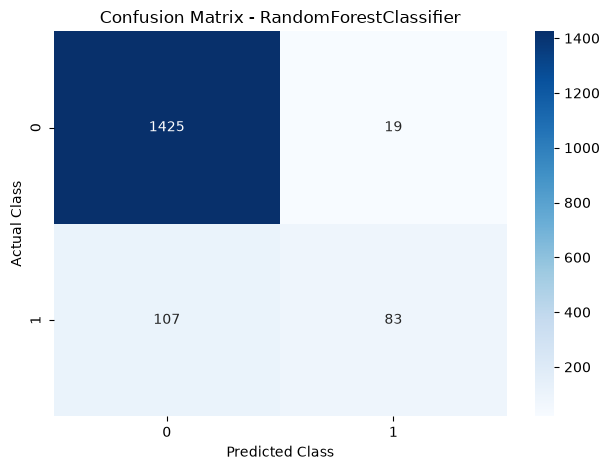

In [26]:

cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - RandomForestClassifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


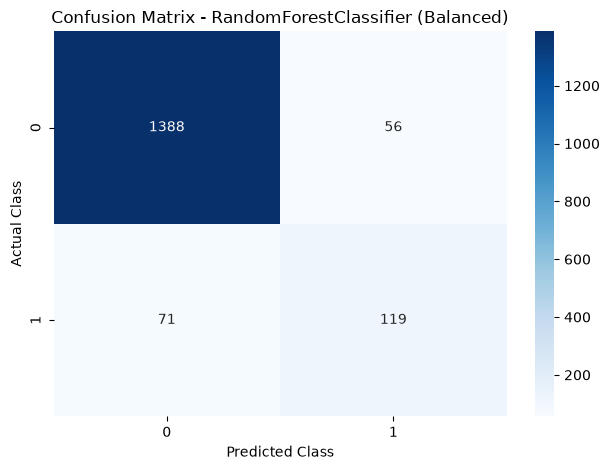

In [27]:

cm_rf_bal = confusion_matrix(y_test, y_pred_rf_bal)

sns.heatmap(cm_rf_bal, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - RandomForestClassifier (Balanced)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


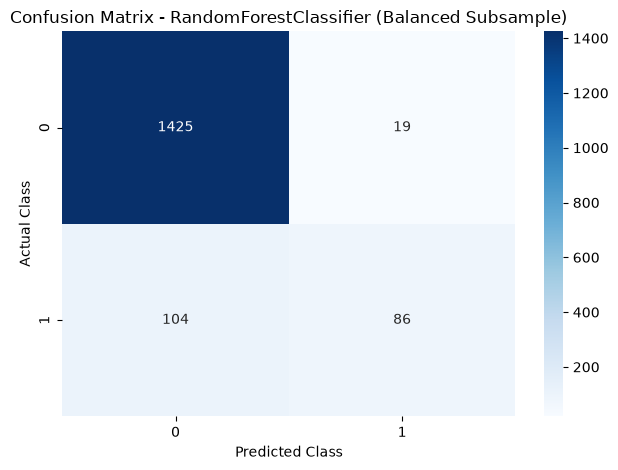

In [28]:

cm_rf_sub = confusion_matrix(y_test, y_pred_rf_sub)

sns.heatmap(cm_rf_sub, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - RandomForestClassifier (Balanced Subsample)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()



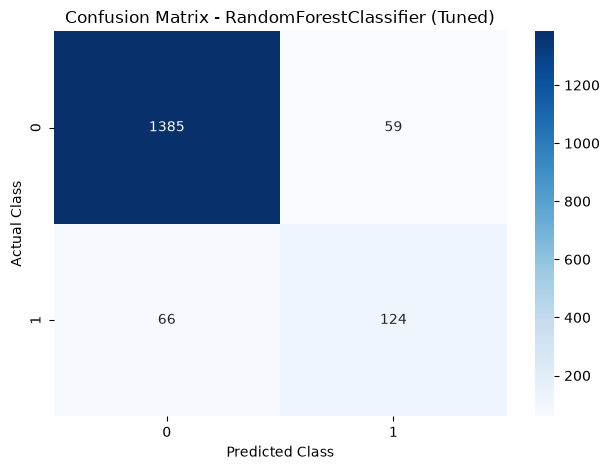

In [29]:

cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)

sns.heatmap(cm_rf_tuned, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - RandomForestClassifier (Tuned)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


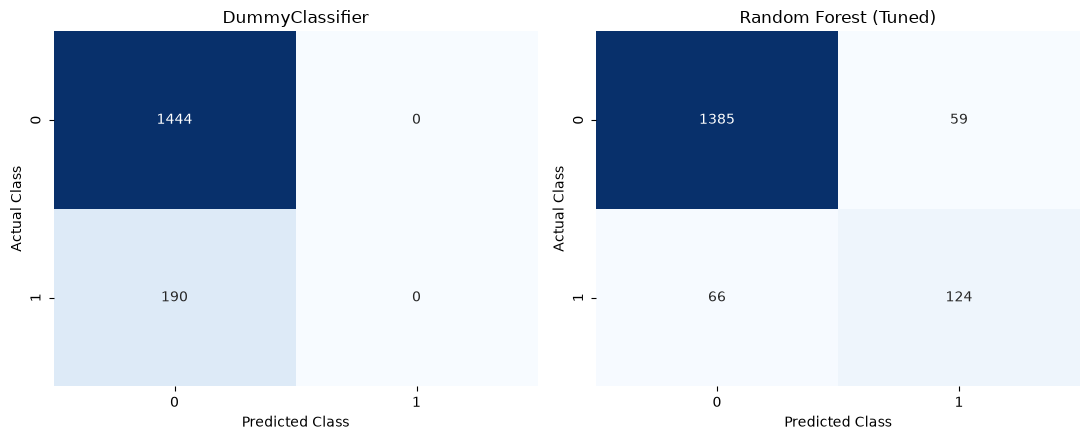

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, cm, titel in zip(
    axes,
    [cm_dummy, cm_rf_tuned],
    ["DummyClassifier", "Random Forest (Tuned)"]
):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(titel)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.savefig("images/confusion_matrices.png", dpi=150)
plt.show()

### **Conclusion**
---
The tuned Random Forest achieved the best F1-score for the active class, with a value of 0.66.

Class weighting made the biggest difference, improving the Random Forest's F1-score from 0.57 to 0.65. Hyperparameter tuning added a further 0.01.

The results show that accuracy alone is not enough to evaluate models on an imbalanced dataset.